In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from sbi import analysis, utils
from sbi.inference import NPE, simulate_for_sbi
from sbi.neural_nets import posterior_nn
from sbi.utils.user_input_checks import (
    check_sbi_inputs,
    process_prior,
    process_simulator,
)
from classification import make_preds_accumul

seed = 0
torch.manual_seed(seed);

from pyriemann.estimation import Xdawn
import sys

sys.path.append('D:/s.velut/Documents/These/Protheus_PHD/Scripts')
from Alignments.riemannian import compute_riemannian_alignment
from EEG2CodeKeras import EEG2Code
import keras
from EEGModels import EEGNet
from pyriemann.utils.mean import mean_covariance
from pyriemann.estimation import Xdawn
from Alignments.covariance import compute_covariances
from Alignments.riemannian import compute_riemannian_alignment
from imblearn.under_sampling import RandomUnderSampler
from _utils import make_preds_accumul_aggresive
from sklearn.metrics import balanced_accuracy_score
from sbi.neural_nets.embedding_nets import CNNEmbedding
from zuko.nn import MLP
from torch.nn import RNN, LSTM
import keras


import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pyntbci.utilities import correlation
from collections import OrderedDict
from typing import Tuple
import pyntbci
import scipy.io
from simulated_cvep.forward_model import gaussian, fwd
import seaborn as sns

from simulated_cvep import forward_model

sys.path.insert(0,"D:/s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link/")
from STLDataLoader import STLDataLoader
from utils import balance

c:\Users\s.velut\AppData\Local\anaconda3\envs\sbi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Overall project

the aim is to connect a classifier that detect the code frame by frame. Then we train a SBI with the detected code to get the parameters

## Get the code

### Get the data

In [2]:
def full_preprocessed_data(path,participant):
    return np.load(path+"full_preprocess_data_"+participant+".npy")

In [3]:
participants = ['P1','P2','P3','P4','P5','P6','P7','P8','P9','P10',\
                    'P11','P12','P13','P14','P15','P16','P17','P18','P19','P20',\
                    'P21','P22','P23','P24']
path = 'D:/s.velut/Documents/These/Protheus_PHD/Data/Dry_Ricker'
n_class = 5
n_cal = 6 
sfreq = 500

# get the data
dl = STLDataLoader(path, 1, 45, 0.35, sfreq, 60, "time_sample", participants, 5)
raw_data = dl.load_data()
Xall, Yall, domainsall, codesdict, labels_code = dl.get_epochs(raw_data)
trials,trial_labels = dl.get_trials(raw_data)
# trials_preproc = trials[:,:10].copy()
codes = np.array([codesdict[i] for i in range(len(codesdict))],dtype=np.uint8)

X_preproc = np.array([full_preprocessed_data('/'.join(['D:/s.velut/Documents/These/Protheus_PHD/Data/STL',"ws"+str(0.35),"time_sample","data",'']),parti) for parti in participants])
for i in range(Xall.shape[0]):
    xdawn = Xdawn(nfilter=4,classes=[1],estimator='lwf')
    X_std = Xall[i][:int(n_cal*n_class*(2.2-0.35)*sfreq)].std(axis=0)
    temp_X = Xall[i][:int(n_cal*n_class*(2.2-0.35)*sfreq)]/(X_std + 1e-8)
    temp_trial = trials[i]/(trials[i][:n_cal*n_class].std(axis=0) + 1e-8)
    xdawn = xdawn.fit(temp_X,Yall[i][:int(n_cal*n_class*(2.2-0.35)*sfreq)])
    print('transform trial')
    temp_trial = xdawn.transform(temp_trial)
    trials[i] = np.hstack([temp_trial,np.tile(np.mean(temp_trial,axis=0),(temp_trial.shape[0],1,1))])
    trials[i] = compute_riemannian_alignment(trials[i], mean=None, dtype='real')

ind_part = 16

Sampling frequency of the instance is already 500.0, returning unmodified.


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


Sampling frequency of the instance is already 500.0, returning unmodified.
Sampling frequency of the instance is already 500.0, returning unmodified.
Sampling frequency of the instance is already 500.0, returning unmodified.


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participant

Sampling frequency of the instance is already 500.0, returning unmodified.
Sampling frequency of the instance is already 500.0, returning unmodified.
Sampling frequency of the instance is already 500.0, returning unmodified.


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_

... (10 outputs left out)

Sampling frequency of the instance is already 500.0, returning unmodified.
Sampling frequency of the instance is already 500.0, returning unmodified.


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participant

Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped
Using data

MemoryError: Unable to allocate 17.4 GiB for an array with shape (24, 69375, 8, 175) and data type float64

In [4]:
codes

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0

### fit the model and predict 

In [ ]:
def get_train_test_data(Xt, Yt, domainst, labels_code, clf_name, n_class=5, n_cal=4, window_size=0.35, freqwise=500):
    # Initialisation
    nb_sample_cal = int(n_class*n_cal*(2.2-window_size)*freqwise)

    # Get the training data 
    X_train = Xt[:nb_sample_cal]
    Y_train = Yt[:nb_sample_cal]
    domains_train = domainst[:nb_sample_cal]
    X_test = Xt[nb_sample_cal:]
    Y_test = Yt[nb_sample_cal:]
    domains_test = domainst[nb_sample_cal:]
    labels_code_test = labels_code[(n_class*n_cal):]
    # X_std = Xt[:nb_sample_cal].std(axis=0)
    # X_train = X_train/(X_std + 1e-8)
    # X_test = X_test/(X_std + 1e-8)

    X_train, Y_train, domains_train = balance(X_train,Y_train,domains_train)

    return X_train, Y_train, X_test, Y_test, domains_train, domains_test, labels_code_test

In [ ]:
optimizer = keras.optimizers.Adam(learning_rate=1e-3, amsgrad=True)
model = EEG2Code(windows_size = X_preproc[ind_part].shape[-1],
                    n_channel_input = X_preproc[ind_part].shape[-2],
                    optimizer=optimizer,
                    num_epochs=25)

X_train, Y_train, X_test, Y_test, domains_train, domains_test, labels_code_test = get_train_test_data(X_preproc[ind_part],
                                                                                             Yall[ind_part],
                                                                                             domainsall[ind_part],
                                                                                             labels_code,
                                                                                             clf_name="EEG2Code",
                                                                                             n_class=n_class,
                                                                                             n_cal=n_cal,
                                                                                             window_size=0.35,
                                                                                             freqwise=sfreq)


model = model.fit(X_train, Y_train)
y_pred = model.predict(X_test)
Y_pred = np.array([1 if (y >= 0.5) else 0 for y in y_pred])
print("EEG2Code Test Balanced Accuracy: ", balanced_accuracy_score(Y_test, Y_pred))

In [ ]:
n_detecttion_inf = int(n_class*n_cal*(2.2-0.35)*sfreq)
n_detecttion_sup = int((n_class*n_cal+1)*(2.2-0.35)*sfreq)
X_detection = Xall[ind_part][n_detecttion_inf:n_detecttion_sup]
X_std = X_detection.std(axis=0)
X_detection = X_detection/(X_std + 1e-8)
Y_detection = Yall[ind_part][n_detecttion_inf:n_detecttion_sup]

y_pred_detection = model.predict(X_detection)
Y_pred_detection = np.array([1 if (y >= 0.5) else 0 for y in y_pred_detection])

print(Y_pred_detection)

In [ ]:
dl_frame = STLDataLoader(path, 1, 45, 0.35, sfreq, 60, "frame", [participants[ind_part]], 5)
raw_data_frame = dl_frame.load_data()
Xframe, Yframe, domainsframe, _, _ = dl_frame.get_epochs(raw_data_frame)

In [ ]:
X_preproc = np.array([full_preprocessed_data('/'.join(['D:/s.velut/Documents/These/Protheus_PHD/Data/STL',"ws"+str(0.35),"frame","data",'']),parti) for parti in participants[ind_part:ind_part+1]])

n_detecttion_inf = int(n_class*n_cal*(2.2-0.35)*60)
n_detecttion_sup = int((n_class*n_cal+1)*(2.2-0.35)*60)
X_detection = X_preproc[0][n_detecttion_inf:n_detecttion_sup]
# X_std = X_detection.std(axis=0)
# X_detection = X_detection/(X_std + 1e-8)
Y_detection = Yframe[0][n_detecttion_inf:n_detecttion_sup]

y_pred_detection = model.predict(X_detection)
detected_code = np.array([1 if (y >= 0.5) else 0 for y in y_pred_detection])

print(detected_code)

In [ ]:
y_pred_detection = model.predict(X_preproc[0])
# y_pred_detection = model.predict(X_preproc[0]/(np.std(X_preproc[0],axis=0)+1e-8))
Y_pred_detection = np.array([1 if (y >= 0.5) else 0 for y in y_pred_detection])
balanced_accuracy_score(Yframe[0], Y_pred_detection)

## Time for the SBI

### Get the simulator and other components of the SBI
embedding nets, distribution, inferer

In [ ]:
def simulator_model(theta,code = None,codes=codes, only_template=False):
    pr = 60
    length_vep=0.3
    # V = pyntbci.stimulus.make_gold_codes()[subset][0]
    # V = pyntbci.stimulus.modulate(V)
    V = codes.copy()
    
    # V = np.zeros((nclass,ntimes))
    # for k in range(nclass):
    #     code_pos = 0
    #     count = 0
    #     for idx in range(ntimes):
    #         if idx/fs >= (code_pos+1)/60:
    #             code_pos += 1 
    #         V[k,count] = int(codes[k][code_pos])
    #         count += 1
    # V = torch.Tensor(V)
    V = torch.repeat_interleave(torch.tensor(V), int(500 / pr),dim=1)
    # V = torch.repeat_interleave(torch.tensor(np.tile(V,5)), int(500 / pr),dim=1)
    # V = torch.Tensor(np.concatenate([V[:,0:1],np.diff(V)],axis=1)%255)
    # print(V[0,:40])
    t = torch.arange(0, length_vep, 1 / 500)

    sim_vep, sim_signal = fwd(t, V, theta, 0)

    noise=0
    snr = 0.1
    sig_avg = torch.mean(sim_signal**2,axis=1)
    sig_avg_db = 10 * np.log10(sig_avg)
    # Calculate noise according to [2] then convert to watts
    noise_avg_db = sig_avg_db - 1/snr
    noise_avg = 10 ** (noise_avg_db / 10)
    # Generate an sample of white noise
    mean_noise = 0
    noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), sim_signal.shape)

    if code is None:
        code = np.arange(0,V.shape[0],1)
    if only_template==False:
        return sim_signal[code]+noise[code]
    else:
        return sim_signal[code]

In [ ]:
theta = torch.tensor( #shape of (n_peaks, 3 {delay, amplitude, std}) 
            [0.14,0.2,0.27, -4,  2, -3, 0.015, 0.020, 0.018])

X = simulator_model(theta,0,[detected_code,detected_code],only_template=False)
Xcode = simulator_model(theta,0,[codes[1],codes[2]],only_template=False)

plt.plot(np.linspace(0,len(X[:500])/500,len(X[:500])),X[:500])
plt.plot(np.linspace(0,len(Xcode[:500])/500,len(Xcode[:500])),Xcode[:500])
X.shape

In [ ]:
class SummaryRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SummaryRNN, self).__init__()

        self.rnn = nn.RNN(input_size, hidden_size)
        self.h2o = nn.Linear(hidden_size, output_size)
        self.relu = nn.ReLU()

    def forward(self, input):
        rnn_out, hidden = self.rnn(torch.unsqueeze(input,dim=1))
        output = self.h2o(rnn_out)
        output = self.relu(output)

        return output.squeeze(1)

In [ ]:
embedding_net = SummaryRNN(input_size=888, hidden_size=128, output_size=20)
prior = utils.BoxUniform(low=torch.FloatTensor([0.127,0.17,0.26,0,-1,0,0.005,0.025,0.005]), high=torch.FloatTensor([0.187,0.23,0.3,1,0,1,0.015,0.035,0.015]))
prior, num_parameters, prior_returns_numpy = process_prior(prior)
simulator_wrapper = process_simulator(lambda x: simulator_model(x,0,[detected_code,detected_code]), prior, prior_returns_numpy)
check_sbi_inputs(simulator_wrapper, prior)


### Create the simulation data

In [ ]:
num_simulations = 30_000
theta, x = simulate_for_sbi(simulator_wrapper, prior, num_simulations=num_simulations)
x = torch.reshape(x,(-1,x.shape[-1]))

# instantiate the neural density estimator
neural_posterior = posterior_nn(model="nsf", embedding_net=embedding_net)

# setup the inference procedure with NPE
inferer = NPE(prior=prior, density_estimator=neural_posterior)

### Train the NPE

In [ ]:
density_estimator = inferer.append_simulations(theta, x).train(training_batch_size=256,stop_after_epochs=35,max_num_epochs=300)
posterior = inferer.build_posterior(density_estimator)

In [ ]:
torch.save(posterior,"D:/s.velut/Documents/These/DCC/SBI/overall_posterior"+str(ind_part)+".pkl")
torch.save(inferer,"D:/s.velut/Documents/These/DCC/SBI/overall_inferer"+str(ind_part)+".pkl")

In [ ]:
trials[0,30].shape

## Evaluate the model

In [ ]:
detected_code, codes

In [ ]:
posterior = torch.load("D:/s.velut/Documents/These/DCC/SBI/overall_posterior"+str(ind_part)+".pkl",weights_only=False)
inferer = torch.load("D:/s.velut/Documents/These/DCC/SBI/overall_inferer"+str(ind_part)+".pkl",weights_only=False)
X0 = trials[ind_part,0,0,:888]

In [ ]:
samples = posterior.set_default_x(X0).sample((10000,))
x_predictive = [simulator_model(s,code=1,codes=codes[:,:111]) for s in samples]
plt.plot(torch.mean(torch.Tensor(np.array(x_predictive)), axis=0).numpy()/np.linalg.norm(torch.mean(torch.Tensor(np.array(x_predictive)), axis=0).numpy()),color=("blue"))
plt.plot(X0/np.linalg.norm(X0),color=("red"),alpha=0.5)

In [ ]:
xemp = X0
sl = posterior.set_default_x(xemp).sample((1000,))
hist = [np.histogram(sl[:,i], bins=500) for i in range(sl.shape[1])]
ind_max = [np.argmax(hist[i][0]) for i in range(len(hist))]
theta_obs = torch.Tensor([hist[i][1][ind_max[i]] for i in range(len(ind_max))])

true_parameter = torch.as_tensor([0.147,0.21, 0.28, 0.2, -0.3, 0.2, 0.007, 0.025, 0.008]) #TODO change

fig, ax = analysis.pairplot(
    sl,
    points=true_parameter,
    labels=[r"$\theta_1$", r"$\theta_2$", r"$\theta_3$", r"$\theta_4$", r"$\theta_5$", r"$\theta_6$",r"$\theta_7$", r"$\theta_8$", r"$\theta_9$"],
    # limits=[[0.050, 0.500],[0.050, 0.500],[0.050, 0.500], [-10, 0.0], [0, 10.0], [-10, 0.0], [0.005, 0.05], [0.005, 0.05], [0.005, 0.05]],
    limits=[[0.127, 0.187],[0.17, 0.23],[0.26, 0.3], [0, 1], [-1, 0], [0, 1], [0.005, 0.015], [0.025, 0.035], [0.005, 0.015]],
    fig_kwargs=dict(
        points_colors="r",
        points_offdiag={"markersize": 6},
    ),
    figsize=(5, 5),
)

In [ ]:
from sbi.diagnostics.lc2st import LC2ST

torch.manual_seed(0) # seed for reproducibility
thetas_star = prior.sample((3,))
xs_star = torch.tensor(np.array([simulator_model(thetas_star[i],0,[detected_code,detected_code]).numpy() for i in range(thetas_star.shape[0])]), dtype=torch.float32)
print(xs_star.shape)
post_samples_star = posterior.sample_batched((10000,), x=xs_star).permute(1,0,2)
# sample calibration data
theta_cal = prior.sample((1000,))
x_cal = torch.tensor(np.array([simulator_model(theta_cal[i],0,[detected_code,detected_code]).numpy() for i in range(theta_cal.shape[0])]), dtype=torch.float32)
post_samples_cal = posterior.sample_batched((1,), x=x_cal, max_sampling_batch_size=10)[0]

# set up the LC2ST: train the classifiers
lc2st = LC2ST(
    thetas=theta_cal,
    xs=x_cal,
    posterior_samples=post_samples_cal,
    classifier="mlp",
    num_ensemble=1, # number of classifiers for the ensemble
)
_ = lc2st.train_under_null_hypothesis() # over 100 trials under (H0)
_ = lc2st.train_on_observed_data() # on observed data

# Define significance level for diagnostics
conf_alpha = 0.05

In [ ]:
from sbi.analysis.plot import pp_plot_lc2st

fig, axes = plt.subplots(1,len(thetas_star), figsize=(12,3))
for i in range(len(thetas_star)):
    probs, scores = lc2st.get_scores(
        theta_o=post_samples_star[i],
        x_o=xs_star[i],
        return_probs=True,
        trained_clfs=lc2st.trained_clfs
    )
    T_data = lc2st.get_statistic_on_observed_data(
        theta_o=post_samples_star[i],
        x_o=xs_star[i]
    )
    T_null = lc2st.get_statistics_under_null_hypothesis(
        theta_o=post_samples_star[i],
        x_o=xs_star[i]
    )
    p_value = lc2st.p_value(post_samples_star[i], xs_star[i])
    reject = lc2st.reject_test(post_samples_star[i], xs_star[i], alpha=conf_alpha)

    # plot 95% confidence interval
    quantiles = np.quantile(T_null, [0, 1-conf_alpha])
    axes[i].hist(T_null, bins=50, density=True, alpha=0.5, label="Null")
    axes[i].axvline(T_data, color="red", label="Observed")
    axes[i].axvline(quantiles[0], color="black", linestyle="--", label="95% CI")
    axes[i].axvline(quantiles[1], color="black", linestyle="--")
    axes[i].set_xlabel("Test statistic")
    axes[i].set_ylabel("Density")
    axes[i].set_xlim(-0.01,0.25)
    axes[i].set_title(
        f"observation {i+1} \n p-value = {p_value:.3f}, reject = {reject}"
    )
axes[-1].legend(bbox_to_anchor=(1.1, .5), loc='center left')
plt.show()


# P-P plots

fig, axes = plt.subplots(1,len(thetas_star), figsize=(12,3))
for i in range(len(thetas_star)):
    probs_data, _ = lc2st.get_scores(
        theta_o=post_samples_star[i],
        x_o=xs_star[i],
        return_probs=True,
        trained_clfs=lc2st.trained_clfs
    )
    probs_null, _ = lc2st.get_statistics_under_null_hypothesis(
        theta_o=post_samples_star[i],
        x_o=xs_star[i],
        return_probs=True
    )

    pp_plot_lc2st(
        probs=[probs_data],
        probs_null=probs_null,
        conf_alpha=conf_alpha,
        labels=["Classifier probabilities \n on observed data"],
        colors=["red"],
        ax=axes[i],
    )
    axes[i].set_title(f"PP-plot for observation {i+1}")
axes[-1].legend(bbox_to_anchor=(1.1, .5), loc='center left')
plt.show()

## Detection of class

In [ ]:
def cross_validate(X_emp, X_syn, y, V,y_syn=None, n_folds=4):
    if y_syn is None:
        y_syn = y.copy()
    accuracy = np.zeros((4, n_folds))
    folds = np.arange(n_folds).repeat(X_emp.shape[0] / n_folds)[:X_emp.shape[0]]
    folds_sim = np.arange(n_folds).repeat(X_syn.shape[0] / n_folds)[:X_syn.shape[0]]
    for i_fold in range(n_folds):
        
        X_emp_trn = X_emp[folds != i_fold, :, :]
        X_emp_tst = X_emp[folds == i_fold, :, :]

        X_syn_trn = X_syn[folds_sim != i_fold, :, :]
        X_syn_tst = X_syn[folds_sim == i_fold, :, :]

        y_trn = y[folds != i_fold]
        y_trn_syn = y_syn[folds_sim != i_fold]
        y_tst = y[folds == i_fold]
        y_tst_syn = y_syn[folds_sim == i_fold]
        
        rcca = pyntbci.classifiers.rCCA(stimulus=V, fs=500, event="id", onset_event=False, encoding_length=0.3)

        # Emp to emp
        rcca.fit(X_emp_trn, y_trn)
        yh_tst = rcca.predict(X_emp_tst)
        accuracy[0, i_fold] = np.mean(yh_tst == y_tst)

        # Emp to syn
        rcca.fit(X_emp_trn, y_trn)
        yh_tst = rcca.predict(X_syn_tst)
        accuracy[1, i_fold] = np.mean(yh_tst == y_tst_syn)

        # Syn to emp
        rcca.fit(X_syn_trn, y_trn_syn)
        yh_tst = rcca.predict(X_emp_tst)
        accuracy[2, i_fold] = np.mean(yh_tst == y_tst)

        # Syn to syn
        rcca.fit(X_syn_trn, y_trn_syn)
        yh_tst = rcca.predict(X_syn_tst)
        accuracy[3, i_fold] = np.mean(yh_tst == y_tst_syn)
    return accuracy

In [ ]:
y_pred_all = []
y_pred_all2 = []
Xsim = []
ysim = []
nfold = 10
y = labels_code[0]
y_true = y
X = trials[ind_part,:,0:1,:888]/np.linalg.norm(trials[ind_part,:,0:1,:888])
codes = np.array([codesdict[i] for i in range(len(codesdict))],dtype=np.uint8)

for i in range(X.shape[0]):
    xemp = X[i]
    sl = posterior.set_default_x(xemp).sample((1000,))
    hist = [np.histogram(sl[:,i], bins=500) for i in range(sl.shape[1])]
    ind_max = [np.argmax(hist[i][0]) for i in range(len(hist))]
    theta_obs = torch.Tensor([hist[i][1][ind_max[i]] for i in range(len(ind_max))])
    # theta_obs = torch.as_tensor([0.157,0.2, 0.29, 0.000025, -0.00005, 0.000001, 0.01, 0.03, 0.01])

    Xsim.append([simulator_model(theta_obs,only_template=True,code=j).numpy() for j in range(5)])
    ysim.append(np.linspace(0,5-1,5).astype(np.uint8))
Xsim = np.concatenate(Xsim,axis=0)
ysim = np.concatenate(ysim,axis=0)

accuracy = cross_validate(X, np.expand_dims(Xsim,1), y_true, codes, y_syn=ysim,n_folds=5)
print("Emp>emp:", accuracy[0, :].mean())
print("Emp>syn:", accuracy[1, :].mean())
print("Syn>emp:", accuracy[2, :].mean())
print("Syn>syn:", accuracy[3, :].mean())

In [ ]:
y_pred_all = []
y_pred_all2 = []
nfold = 1
y_true = y
X = trials[ind_part,:,0:1,:888]/np.linalg.norm(trials[ind_part,:,0:1,:888])
# X = torch.Tensor([np.array(compute_summary_statistics(xk)) for xk in X])
codes = np.array([codesdict[i] for i in range(len(codesdict))],dtype=np.uint8)

# y_true = mat1["y"][:,0]
# X = mat1["X"][4].T[:,:ntimes]/np.linalg.norm(mat1["X"][4].T[:,:ntimes])
# codes = mat['V'].T[:,:]  #132 if X is 1056 shape
for i in range(X.shape[0]):
    y_pred = []
    corr = []
    for n in range(nfold):
    # if mat2["y"][i][0] == 13:
        xemp = X[i]
        # xemp = torch.Tensor(np.array(compute_summary_statistics(xemp.numpy())))
        sl = posterior.set_default_x(xemp).sample((1000,))
        hist = [np.histogram(sl[:,i], bins=500) for i in range(sl.shape[1])]
        ind_max = [np.argmax(hist[i][0]) for i in range(len(hist))]
        theta_obs = torch.Tensor([hist[i][1][ind_max[i]] for i in range(len(ind_max))])
        # theta_obs = torch.as_tensor([0.18,0.23, 0.27, -0.0015, 0.006, -0.004, 0.01, 0.01, 0.005])
        # theta_obs = torch.as_tensor([0.157,0.2, 0.29, 0.000025, -0.00005, 0.000001, 0.01, 0.03, 0.01])
        # template_pred = simulator_model(theta_obs,code=i,only_template=True)

        # print(theta_obs)
        # corr.append([correlation(xemp,torch.Tensor(np.array(compute_summary_statistics(simulator_model(theta_obs,code=j,only_template=True).numpy())))) for j in range(5)])
        # y_pred.append(np.argmax([correlation(xemp,torch.Tensor)(np.array(compute_summary_statistics(simulator_model(theta_obs,code=j,only_template=True).numpy()))) for j in range(5)])+1)
        corr.append([correlation(xemp,np.abs(simulator_model(theta_obs,code=j,only_template=True).numpy()[:888])) for j in range(5)])
        y_pred.append(np.argmax([correlation(xemp,np.abs(simulator_model(theta_obs,code=j,only_template=True).numpy()[:888])) for j in range(5)]))
        # print(corr)
        # print(f"ind max of empircial data {i} is : {y_pred}  \n ")
    y_pred_all.append(max(y_pred,key=y_pred.count))
    y_pred_all2.append(np.argmax(np.concatenate(corr))%5)
print(np.mean(y_pred_all==y_true), np.mean(y_pred_all2==y_true))

# Visualize results

## Get results

In [2]:
# overall_results = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_"+str(i)+".npy") for i in range(24)])
# CV_overall_results = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_CV_accuracy_participant_"+str(i)+".npy") for i in range(24)])

overall_results_RNN = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN"+str(i)+".npy") for i in range(24)])
overall_results_RNN2 = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN"+str(i)+".npy") for i in range(24)])
overall_results_RNN_FA = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_allamp"+str(i)+".npy") for i in range(24)])
overall_results_RNN2_FA = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN_allamp"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Inv"+str(i)+".npy") for i in range(24)])
overall_results_RNN2_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN_Inv"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Inv10 = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Inv10"+str(i)+".npy") for i in range(24)])
overall_results_RNN2_Inv10 = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN_Inv10"+str(i)+".npy") for i in range(24)])
overall_results_RNN_InvMore = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_InvMore"+str(i)+".npy") for i in range(24)])
overall_results_RNN2_InvMore = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN_InvMore"+str(i)+".npy") for i in range(24)])
overall_results_RNN_InvBiggestAmp = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_InvBiggestAmp"+str(i)+".npy") for i in range(24)])
overall_results_RNN2_InvBiggestAmp = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_2_participant_RNN_InvBiggestAmp"+str(i)+".npy") for i in range(24)])
overall_results_RNN_InvAbs = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_InvAbs"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Abs = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Abs"+str(i)+".npy") for i in range(24)])
overall_results_RNN_NoPreproc = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_NoPreproc"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Inv_Perso"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Inv_AllCode = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Inv_AllCode"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Inv_Order = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Inv_Order"+str(i)+".npy") for i in range(24)])

overall_results_RNN_Sim2Sim_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Sim2Sim_Inv"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Sim2Sim_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Sim2Sim_Inv_Perso"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Sim2Sim_Inv_AllCode = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Sim2Sim_Inv_AllCode"+str(i)+".npy") for i in range(24)])
overall_results_RNN_Sim2Sim_Inv_Order = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_accuracy_participant_RNN_Sim2Sim_Inv_Order"+str(i)+".npy") for i in range(24)])



# CV_overall_results_RNN = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/overall_CV_accuracy_participant_RNN_"+str(i)+".npy") for i in range(24)])

C:\Users\s.velut\AppData\Local\Temp\ipykernel_6064\555967739.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["General prior","Adapted prior","General Prior all Code","Order","General prior - simulated data","Adapted prior - simulated data", "General Prior all Code -\n simulated data","ORder -simulated data"], rotation=90)


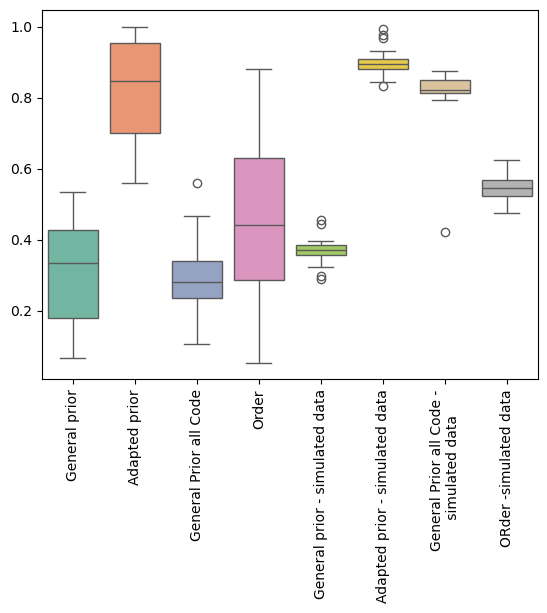

In [3]:
# ax =sns.boxplot(data=[overall_results_RNN[:,0], overall_results_RNN_FA[:,0],
#                       overall_results_RNN_Inv[:,0],overall_results_RNN_Inv_Perso[:,0],
#                       overall_results_RNN_InvMore[:,0],overall_results_RNN_InvBiggestAmp[:,0],
#                       overall_results_RNN_NoPreproc[:,0], overall_results_RNN_Abs[:,0], overall_results_RNN_Sim2Sim_Inv[:,0]], palette="Set2")
ax =sns.boxplot(data=[overall_results_RNN_Inv[:,0],overall_results_RNN_Inv_Perso[:,0], overall_results_RNN_Inv_AllCode[:,0], overall_results_RNN_Inv_Order[:,0],
                      overall_results_RNN_Sim2Sim_Inv[:,0], overall_results_RNN_Sim2Sim_Inv_Perso[:,0], overall_results_RNN_Sim2Sim_Inv_AllCode[:,0], overall_results_RNN_Sim2Sim_Inv_Order[:,0]
                      ], palette="Set2")
ax.set_xticklabels(["General prior","Adapted prior","General Prior all Code","Order","General prior - simulated data","Adapted prior - simulated data", "General Prior all Code -\n simulated data","ORder -simulated data"], rotation=90)
# plt.savefig("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/results.pdf", format="pdf")

plt.show()

In [4]:
overall_results_RNN_Inv.mean(), overall_results_RNN_Inv_Perso.mean(), overall_results_RNN_Sim2Sim_Inv.mean(), overall_results_RNN_Sim2Sim_Inv_Perso.mean(), overall_results_RNN_Inv_AllCode.mean(),overall_results_RNN_Sim2Sim_Inv_AllCode.mean()

(np.float64(0.30888888888888894),
 np.float64(0.8266666666666667),
 np.float64(0.36833333333333335),
 np.float64(0.8976666666666667),
 np.float64(0.29277777777777775),
 np.float64(0.8130000000000001))

In [5]:
# ax =sns.boxplot(data=[overall_results[:,0], CV_overall_results[:,0],CV_overall_results[:,1],CV_overall_results[:,2],CV_overall_results[:,3]], palette="Set2")
# ax.set_xticklabels(["own correlation","Emp>emp","Emp>syn","Syn>emp","Syn>syn"])
# plt.show()

# Curve fitting

In [4]:
overall_theta_RNN_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Inv"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Inv_Perso"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Inv_AllCode = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Inv_AllCode"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Inv_Order = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Inv_Order"+str(i)+".npy") for i in range(24)])

overall_theta_RNN_Sim2Sim_obs_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_true_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_obs_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv_Perso"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_true_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv_Perso"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_obs_Inv_AllCode = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv_AllCode"+str(i)+".npy") for i in range(24)]).reshape(24,250,9)
overall_theta_RNN_Sim2Sim_true_Inv_AllCode = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv_AllCode"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_obs_Inv_Order = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv_Order"+str(i)+".npy") for i in range(24)])
overall_theta_RNN_Sim2Sim_true_Inv_Order = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv_Order"+str(i)+".npy") for i in range(24)])

In [7]:
overall_theta_RNN_Inv_AllCode

array([[ 0.16611578,  0.18706372,  0.24277243, -0.328407  ,  0.41630664,
        -0.06173909,  0.01466103,  0.02966284,  0.01024273],
       [ 0.14135975,  0.10401725,  0.23433997, -0.35968918,  0.44123024,
        -0.2846899 ,  0.01030761,  0.01847045,  0.01126241],
       [ 0.1685929 ,  0.10733134,  0.30336633, -0.32046062,  0.85643995,
        -0.3028111 ,  0.02517282,  0.01807912,  0.01024992],
       [ 0.16686702,  0.16751078,  0.24306361, -0.06021607,  0.56217057,
        -0.24400258,  0.01149292,  0.0293558 ,  0.01198899],
       [ 0.16955736,  0.10435524,  0.23256347, -0.4075207 ,  0.4419386 ,
        -0.3714713 ,  0.02037619,  0.01787672,  0.0114454 ],
       [ 0.16442096,  0.15385321,  0.23172766, -0.94080883,  0.4533118 ,
        -0.08359015,  0.01545806,  0.02548572,  0.01025787],
       [ 0.13830915,  0.22762458,  0.23356327, -1.256481  ,  0.4029617 ,
        -0.05509114,  0.01987225,  0.03814099,  0.01083537],
       [ 0.12235063,  0.13237543,  0.23296285, -0.33640045,  0

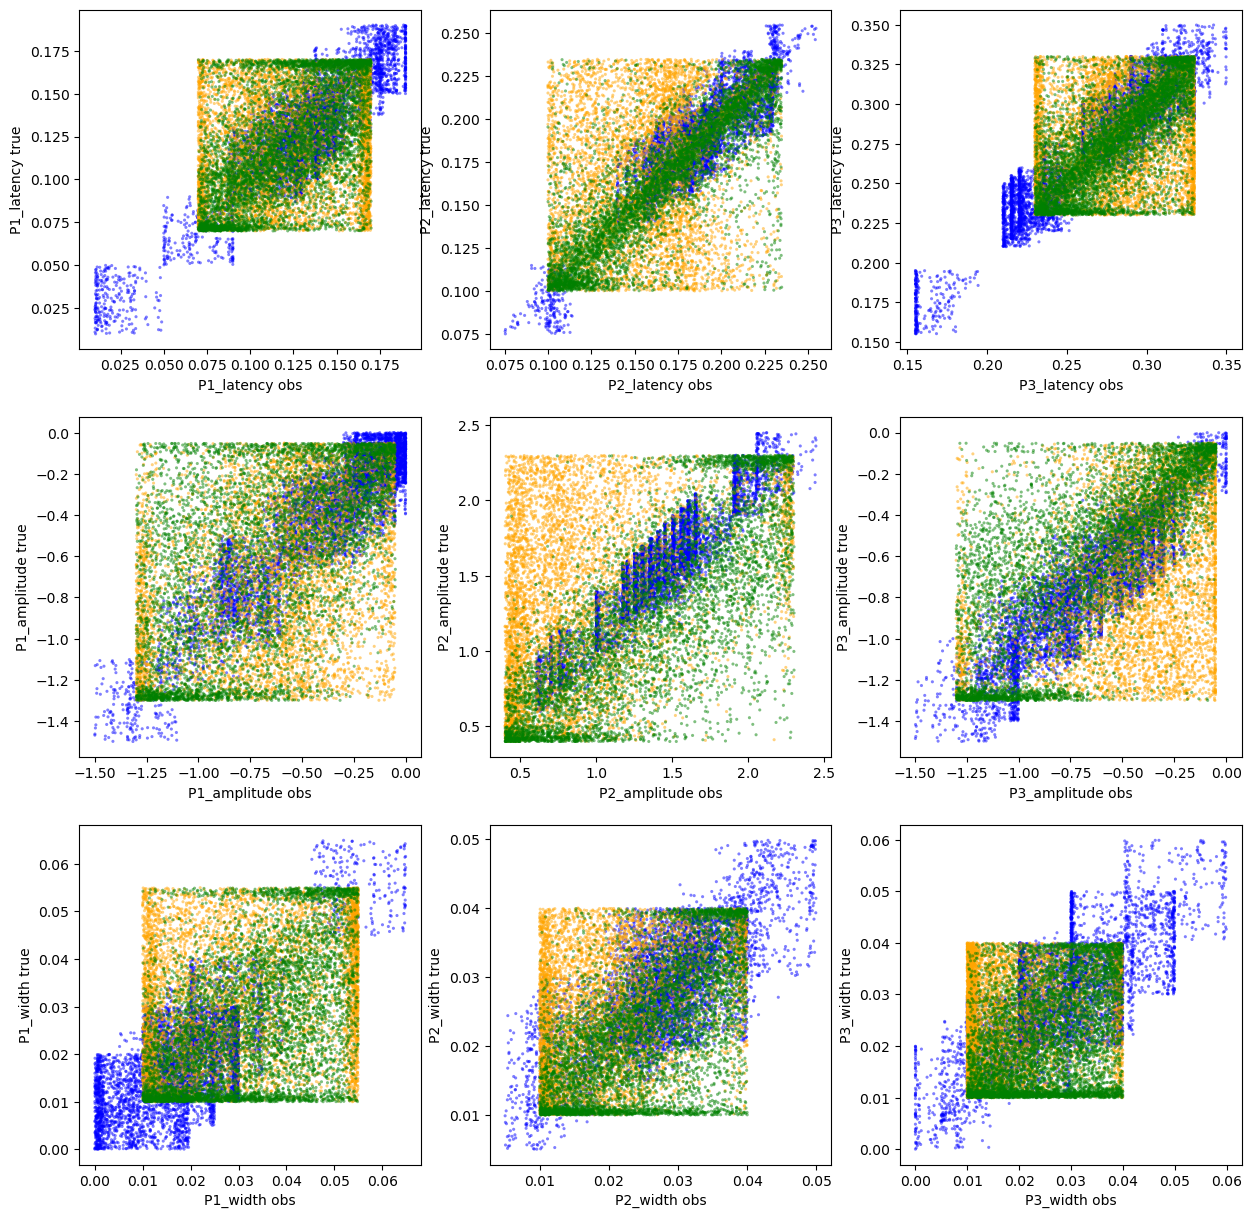

In [5]:
params_name = ["P1_latency","P2_latency","P3_latency","P1_amplitude","P2_amplitude","P3_amplitude","P1_width","P2_width","P3_width"]
plt.figure(figsize=(15,15))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.scatter(overall_theta_RNN_Sim2Sim_obs_Inv_Perso[:,:,i], overall_theta_RNN_Sim2Sim_true_Inv_Perso[:,:,i], color="blue", alpha=0.5, s=5,edgecolors='none')
    plt.scatter(overall_theta_RNN_Sim2Sim_obs_Inv[:,:,i], overall_theta_RNN_Sim2Sim_true_Inv[:,:,i], color="orange", alpha=0.5, s=5,edgecolors='none')
    plt.scatter(overall_theta_RNN_Sim2Sim_obs_Inv_AllCode[:,:,i], overall_theta_RNN_Sim2Sim_true_Inv_AllCode[:,:,i], color="green", alpha=0.5, s=5,edgecolors='none')
    plt.xlabel(params_name[i]+" obs")
    plt.ylabel(params_name[i]+" true")

In [5]:
import mne

def get_alldata(subj):
    to_remove = []
    dl = STLDataLoader('D:/s.velut/Documents/These/Protheus_PHD/Data/Dry_Ricker/', 1, 45, 0.35, 500, 60, "time_sample", [subj], 5)
    raw_data = dl.load_data()
    X, Y, domains, codesdict, labels_code = dl.get_epochs(raw_data)

    def changeEventID(events, event_id):
            new_dic = {}
            for k in event_id.keys():
                new_dic[k.split('_')[1]] = event_id[k]
                event_id[k] = int(k.split('_')[1])
            for i in range(len(events)):
                events[i][2] = int(new_dic[str(events[i][2])])
            
            return events, event_id 

    for idx in range(len(raw_data[0].annotations.description)):
        if (('boundary' in raw_data[0].annotations.description[idx]) or
            ('BURST' in raw_data[0].annotations.description[idx])):
            to_remove.append(idx)

    to_remove = np.array(to_remove)
    if len(to_remove) > 0:
        raw_data[0].annotations.delete(to_remove)
    temp_event,temp_event_id = mne.events_from_annotations(raw_data[0], event_id='auto', verbose=False)
    temp_event,temp_event_id = changeEventID(temp_event,temp_event_id)
    epochs = mne.Epochs(raw_data[0], temp_event, event_id=temp_event_id, tmin=0, 
                    tmax=2.2, baseline=(None, None), preload=True, verbose=False).resample(480)
    y = epochs.events[..., -1]

    m = epochs.get_data()[0,4,:-1]/np.linalg.norm(epochs.get_data()[0,4,:-1])

    return epochs, y, X, Y, np.array([codesdict[i] for i in range(len(codesdict))],dtype=np.uint8)

def simulator_model(theta,code = None,codes=None, only_template=False):
    pr = 60
    length_vep=0.35
    # V = pyntbci.stimulus.make_gold_codes()[subset][0]
    # V = pyntbci.stimulus.modulate(V)
    V = codes.copy()
    
    # V = np.zeros((nclass,ntimes))
    # for k in range(nclass):
    #     code_pos = 0
    #     count = 0
    #     for idx in range(ntimes):
    #         if idx/fs >= (code_pos+1)/60:
    #             code_pos += 1 
    #         V[k,count] = int(codes[k][code_pos])
    #         count += 1
    # V = torch.Tensor(V)
    V = torch.repeat_interleave(torch.tensor(V), int(500 / pr),dim=1)
    # V = torch.repeat_interleave(torch.tensor(np.tile(V,5)), int(500 / pr),dim=1)
    # V = torch.Tensor(np.concatenate([V[:,0:1],np.diff(V)],axis=1)%255)
    # print(V[0,:40])
    t = torch.arange(0, length_vep, 1 / 500)

    sim_vep, sim_signal = fwd(t, V, theta, 0)

    noise=0
    snr = 0.1
    sig_avg = torch.mean(sim_signal**2,axis=1)
    sig_avg_db = 10 * np.log10(sig_avg)
    # Calculate noise according to [2] then convert to watts
    noise_avg_db = sig_avg_db - 1/snr
    noise_avg = 10 ** (noise_avg_db / 10)
    # Generate an sample of white noise
    mean_noise = 0
    noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), sim_signal.shape)

    if code is None:
        code = np.arange(0,V.shape[0],1)
    if only_template==False:
        return sim_signal[code]+noise[code]
    else:
        return sim_signal[code]
    
def f(t, *pars):
    delays = torch.Tensor(pars[:3]).unsqueeze(1)
    amplitudes = torch.Tensor(pars[3:6]).unsqueeze(1)
    sigmas = torch.Tensor(pars[6:9]).unsqueeze(1)
    vep = gaussian(torch.Tensor(t).unsqueeze(0), delays, amplitudes, sigmas).sum(dim=0)  

    return np.array(vep.numpy(),dtype=np.float64)

length_vep=0.35
t = np.arange(0, length_vep, 1 / 500, dtype=np.float64)

parameters_all_ERP = {"P1":[0.13,0.177,0.235,-0.1,1.7,-0.9,0.01,0.025,0.032],
                  "P2":[0.157,0.21,0.28,-0.3,1.2,-1.2,0.01,0.03,0.02],
                  "P3":[0.107,0.188,0.278,-0.05,1.37,-0.65,0.02,0.02,0.03],
                  "P4":[0.135,0.175,0.24,-1.3,2.1,-1.0,0.02,0.035,0.02],
                  "P5":[0.12,0.187,0.255,-0.2,1.5,-0.7,0.02,0.027,0.03],
                  "P6":[0.15,0.21,0.285,-0.4,1.6,-1.3,0.02,0.04,0.03],
                  "P7":[0.12,0.185,0.31,-0.05,1.5,-1.2,0.02,0.03,0.04],
                  "P8":[0.13,0.183,0.28,-0.4,1.85,-0.7,0.01,0.03,0.05],
                  "P9":[0.125,0.16,0.23,-0.8,1.2,-0.6,0.02,0.03,0.03],
                  "P10":[0.13,0.21,0.31,-0.25,0.9,-0.1,0.02,0.03,0.01],
                  "P11":[0.135,0.174,0.23,-0.5,1.55,-1,0.01,0.026,0.027],
                  "P12":[0.17,0.22,0.31,-0.7,1.45,-0.45,0.015,0.03,0.04],
                  "P13":[0.17,0.235,0.3,-0.8,1.8,-0.5,0.025,0.03,0.02],
                  "P14":[0.11,0.198,0.295,-0.25,1.65,-0.7,0.03,0.03,0.02],
                  "P15":[0.15,0.2, 0.32, -0.1, 0.95, -0.55, 0.01, 0.018, 0.03],
                  "P16":[0.07,0.19, 0.285, -0.45, 1.75, -0.85, 0.03, 0.028, 0.03],
                  "P17":[0.11,0.178,0.235,-0.05,1.7,-0.9,0.01,0.025,0.03],
                  "P18":[0.17,0.215, 0.33, -0.7, 1.5, -0.8, 0.015, 0.04, 0.03],
                  "P19":[0.03,0.095, 0.175, -0.005, 1.45, -0.9, 0.01, 0.032, 0.04],
                  "P20":[0.11,0.2, 0.305, -0.002, 1.4, -0.95, 0.055, 0.03, 0.02],
                  "P21":[0.14,0.182,0.31,-0.85,2.25,-0.4,0.02,0.02,0.03],
                  "P22":[0.12,0.18,0.295,-0.4,1.55,-0.55,0.02,0.03,0.03],
                  "P23":[0.125,0.17,0.24,-0.3,0.8,-0.6,0.015,0.015,0.015],
                  "P24":[0.12,0.165,0.24,-1,2.1,-0.5,0.02,0.03,0.04]
}

In [6]:
class SummaryRNN(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SummaryRNN, self).__init__()

        self.rnn = nn.RNN(input_size, hidden_size)
        self.h2o = nn.Linear(hidden_size, output_size)
        self.relu = nn.ReLU()

    def forward(self, input):
        rnn_out, hidden = self.rnn(torch.unsqueeze(input,dim=1))
        output = self.h2o(rnn_out)
        output = self.relu(output)

        return output.squeeze(1)
    
all_participants = np.array(['P1','P2','P3','P4','P5','P6','P7','P8','P9','P10',\
                    'P11','P12','P13','P14','P15','P16','P17','P18','P19','P20',\
                    'P21','P22','P23','P24'])
participants = all_participants
    
X_sim = []
Y_sim = []
n_part = 0

epochs,trial_labels,Xall,Yall,codes = get_alldata(participants[n_part])
print(trial_labels[20])
trials = epochs.get_data()[:,:,:-1]#/np.linalg.norm(epochs.get_data()[:,:,:-1])
y_true = trial_labels-1

xdawn = Xdawn(nfilter=4,classes=[1],estimator='lwf')
# temp_trial = trials/(trials[:4*5].std(axis=0) + 1e-8)
# xdawn = xdawn.fit(temp_trial[:4*5],trial_labels[:int(4*5)])
X_std = Xall[0][:int(4*5*(2.2-0.35)*500)].std(axis=0)
temp_X = Xall[0][:int(4*5*(2.2-0.35)*500)]/(X_std + 1e-8)
temp_trial = trials/(trials[:4*5].std(axis=0) + 1e-8)
# trials[0] = trials[0]/(trials[0][:4*5].std(axis=0) + 1e-8)
xdawn = xdawn.fit(temp_X,Yall[0][:int(4*5*(2.2-0.35)*500)])
print('transform trial')
temp_trial = xdawn.transform(temp_trial)
trials = np.hstack([temp_trial,np.tile(np.mean(temp_trial,axis=0),(temp_trial.shape[0],1,1))])
trials = compute_riemannian_alignment(trials, mean=None, dtype='real')[:,0,:]

# for j,theta_obs in enumerate(overall_theta_RNN_Sim2Sim_true_Inv[n_part]):
#     x = simulator_model(torch.Tensor(theta_obs),code=j//100,only_template=True, codes=codes).numpy()
#     X_sim.append(x)
#     Y_sim.append(j//100)

# X_sim = np.reshape(X_sim,(-1,np.array(X_sim).shape[-1]))
# Y_sim = np.reshape(Y_sim,-1)
# print(X_sim.shape,Y_sim.shape)
y_pred_all = []
corr = []

posterior = torch.load("D:/s.velut/Documents/These/DCC/SBI/overall_posterior"+str(n_part)+".pkl",weights_only=False)
for i in range(75):
    y_pred = []
    # xemp = X_sim[i][:1056]
    xemp = trials[i][:1056]
    # theta_obs = overall_theta_RNN_Sim2Sim_obs_Inv[n_part,i]
    # sl = posterior.set_default_x(xemp).sample((1000,))
    # hist = [np.histogram(sl[:,i], bins=500) for i in range(sl.shape[1])]
    # plt.scatter(hist[1][1][:500],hist[1][0])
    # plt.scatter(hist[0][1][:500],hist[0][0])
    # ind_max = [np.argmax(hist[i][0]) for i in range(len(hist))]
    # theta_obs = torch.Tensor([hist[i][1][ind_max[i]] for i in range(len(ind_max))])
    theta_obs = overall_theta_RNN_Inv_AllCode[n_part]
    y_pred.append(np.argmax([correlation(xemp,simulator_model(torch.Tensor(theta_obs),code=j,only_template=True, codes=codes).numpy()[:1056]) for j in range(5)]))
    corr.append([correlation(xemp,simulator_model(torch.Tensor(theta_obs),code=j,only_template=True, codes=codes).numpy()[:1056]) for j in range(5)])
    y_pred_all.append(max(y_pred,key=y_pred.count))
# print(Y_sim.shape,np.array(y_pred_all))
# print(np.mean(y_pred_all==Y_sim))
print(np.mean(y_pred_all==y_true))
plt.show()

Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


4
transform trial


C:\Users\s.velut\AppData\Local\Temp\ipykernel_6064\4039915314.py:65: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  sig_avg_db = 10 * np.log10(sig_avg)
C:\Users\s.velut\AppData\Local\Temp\ipykernel_6064\4039915314.py:71: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  noise = np.random.normal(mean_noise, np.sqrt(torch.mean(noise_avg)), sim_signal.shape)


0.25333333333333335


In [7]:
hist[1][0][:500]

Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


... (38 outputs left out)

Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


Sampling frequency of the instance is already 500.0, returning unmodified.
Using data from preloaded Raw for 75 events and 1101 original time points ...
0 bad epochs dropped


D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)
D:\s.velut/Documents/These/Protheus_PHD/Scripts/Sim_Trans_Link\STLDataLoader.py:96: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw_eeglab = [mne.io.read_raw_eeglab(os.path.join(self.path, '_'.join([self.participants[i], 'dryburst100.set'])), preload=True, verbose=False).resample(sfreq=self.sfreq)


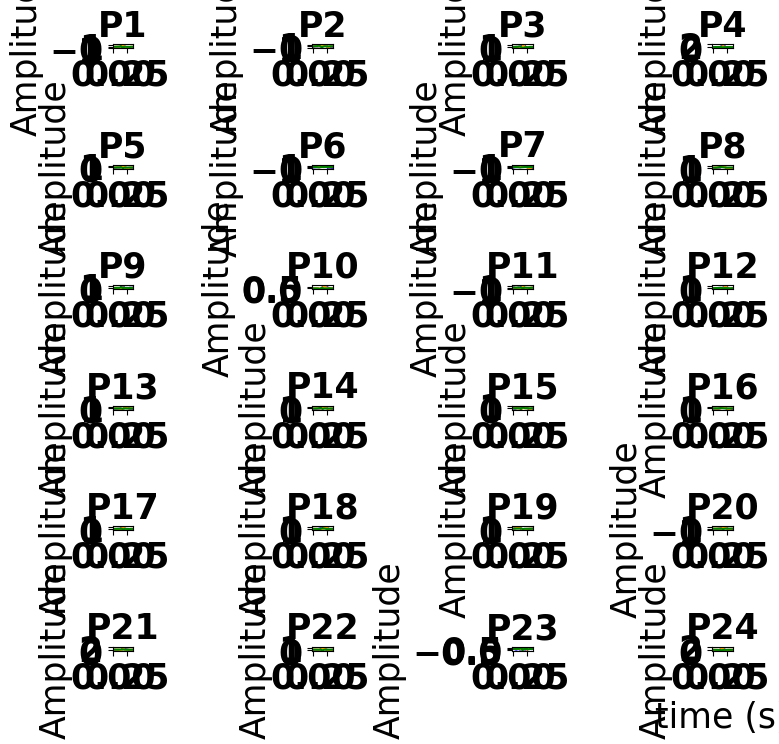

In [12]:
from scipy.optimize import curve_fit
from sklearn.mixture import GaussianMixture
from matplotlib import rcParams

rcParams['font.weight'] = 'bold'
rcParams['font.size'] = '25'

all_participants = np.array(['P1','P2','P3','P4','P5','P6','P7','P8','P9','P10',\
                    'P11','P12','P13','P14','P15','P16','P17','P18','P19','P20',\
                    'P21','P22','P23','P24'])
participants = all_participants

# participants = ["P20", "P21"]

window_size = 0.35
# participants = ['P1','P2','P3','P4']
def full_preprocessed_data(path,participant):
    return np.load(path+"full_preprocess_data_"+participant+".npy")

mse_all = []

fig = plt.figure(figsize=(15,15))
fig.set_figheight(8)
fig.set_figwidth(8)
for ind_part in range(len(participants)):
    epochs,y_code, xsample, y,_ = get_alldata(participants[ind_part])
    X_preproc = np.array(full_preprocessed_data('/'.join(['D:/s.velut/Documents/These/Protheus_PHD/Data/STL',"ws"+str(0.35),"time_sample","data",'']),participants[ind_part]))
    
    # xdawn = Xdawn(nfilter=4,classes=[1],estimator='lwf')
    # X_std = xsample[0][:int(n_cal*n_class*(2.2-window_size)*sfreq)].std(axis=0)
    # temp_X = xsample[0][:int(n_cal*n_class*(2.2-window_size)*sfreq)]/(X_std + 1e-8)
    # xdawn = xdawn.fit(temp_X,y[0][:int(n_cal*n_class*(2.2-window_size)*sfreq)])
    # print('transform trial')
    # temp_X = xdawn.transform(temp_X)
    # X_preproc = np.hstack([temp_X,np.tile(np.mean(temp_X,axis=0),(temp_X.shape[0],1,1))])
    # X_preproc = compute_riemannian_alignment(X_preproc, mean=None, dtype='real')
    if participants[ind_part]=="P2":
        evoked = np.mean(X_preproc[y[0]==1][:,1],axis=0,dtype=np.float64)
        evoked_var = np.std(X_preproc[y[0]==1][:,1],axis=0,dtype=np.float64)
    else:
        evoked = np.mean(X_preproc[y[0]==1][:,0],axis=0,dtype=np.float64)
        evoked_var = np.std(X_preproc[y[0]==1][:,0],axis=0,dtype=np.float64)

    # popt, pcov = curve_fit(f, t, evoked, p0=[0.157,0.20, 0.29, -0.25, 0.9, -0.01, 0.01, 0.03, 0.01])
    popt = parameters_all_ERP[participants[ind_part]] #[0.12,0.165,0.24,-1,2.1,-0.5,0.02,0.03,0.04]
    popt_Perso = overall_theta_RNN_Inv_Perso[np.where(all_participants==participants[ind_part])[0][0]]
    popt_Gen = overall_theta_RNN_Inv[np.where(all_participants==participants[ind_part])[0][0]]
    popt_AllCode = overall_theta_RNN_Inv_AllCode[np.where(all_participants==participants[ind_part])[0][0]]
    sim_vep = f(t,popt[0],popt[1],popt[2],popt[3],popt[4],popt[5],popt[6],popt[7],popt[8])
    sim_vep_Perso = f(t,popt_Perso[0],popt_Perso[1],popt_Perso[2],popt_Perso[3],popt_Perso[4],popt_Perso[5],popt_Perso[6],popt_Perso[7],popt_Perso[8])
    sim_vep_Gen = f(t,popt_Gen[0],popt_Gen[1],popt_Gen[2],popt_Gen[3],popt_Gen[4],popt_Gen[5],popt_Gen[6],popt_Gen[7],popt_Gen[8])
    sim_vep_AllCode = f(t,popt_AllCode[0],popt_AllCode[1],popt_AllCode[2],popt_AllCode[3],popt_AllCode[4],popt_AllCode[5],popt_AllCode[6],popt_AllCode[7],popt_AllCode[8])

    max_ind = np.argmax(np.abs(evoked))
    sign = np.sign(evoked[max_ind])

    mse = np.mean((evoked*sign - sim_vep) ** 2)
    mse_Perso = np.mean((evoked*sign - sim_vep_Perso) ** 2)
    mse_Gen = np.mean((evoked*sign - sim_vep_Gen) ** 2)
    mse_AllCode = np.mean((evoked*sign - sim_vep_AllCode) ** 2)

    mse_all.append([mse,mse_Perso, mse_Gen, mse_AllCode])

    # ax = plt.subplot(2,1,ind_part+1)
    ax = plt.subplot(6,4,ind_part+1)
    plt.plot(t,evoked*sign, label="Empirical", color="blue")
    # plt.fill_between(t, np.subtract(evoked*sign, sign*evoked_var), np.add(evoked*sign, sign*evoked_var), color="blue", alpha=0.2)
    plt.plot(t,sim_vep_Perso, label="within-pp", color="orange")
    plt.plot(t,sim_vep_Gen, label="across-pp", color="green")
    # plt.plot(t,sim_vep_AllCode, label="Gen evoked", color="red")
    # plt.plot(t,sim_vep_inf, label="inf evoked")
    # plt.plot(t,sim_vep_sup, label="max evoked")
    plt.ylabel("Amplitude")

    ax.set_title(participants[ind_part],fontsize=25, fontweight='bold')
plt.xlabel("time (s)")
    
fig.tight_layout()

# plt.legend(loc='center left', bbox_to_anchor=(1, 1.2), fontsize=20)
# plt.savefig('D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/fit_cruves.pdf',bbox_inches='tight',dpi=300)
# plt.show()

In [13]:
mse_all

[[np.float64(0.026070944426938608),
  np.float64(0.08069024016033796),
  np.float64(0.6035343940245583),
  np.float64(0.35089889192728313)],
 [np.float64(0.01005767598170122),
  np.float64(0.03386341941562527),
  np.float64(0.35014712213496246),
  np.float64(0.3518456179178753)],
 [np.float64(0.014466826099122785),
  np.float64(0.08552863428062919),
  np.float64(0.4375411713861183),
  np.float64(0.3861572158397288)],
 [np.float64(0.057608209535930315),
  np.float64(0.2652263819926371),
  np.float64(0.6743031036803473),
  np.float64(0.37625439871218014)],
 [np.float64(0.023554009644616725),
  np.float64(0.07816751686199881),
  np.float64(0.43747253415290516),
  np.float64(0.4859549948374257)],
 [np.float64(0.03575759756974372),
  np.float64(0.21217198187370787),
  np.float64(0.5745193199665166),
  np.float64(0.6516486932109076)],
 [np.float64(0.01398133164408378),
  np.float64(0.050381817181512606),
  np.float64(0.6454797076076184),
  np.float64(0.8221198625320806)],
 [np.float64(0.0304

In [14]:
np.mean(mse_all,axis=0), np.std(mse_all,axis=0)

(array([0.0310841 , 0.10732588, 0.44886212, 0.43728072]),
 array([0.01826337, 0.05995476, 0.16806031, 0.18270764]))

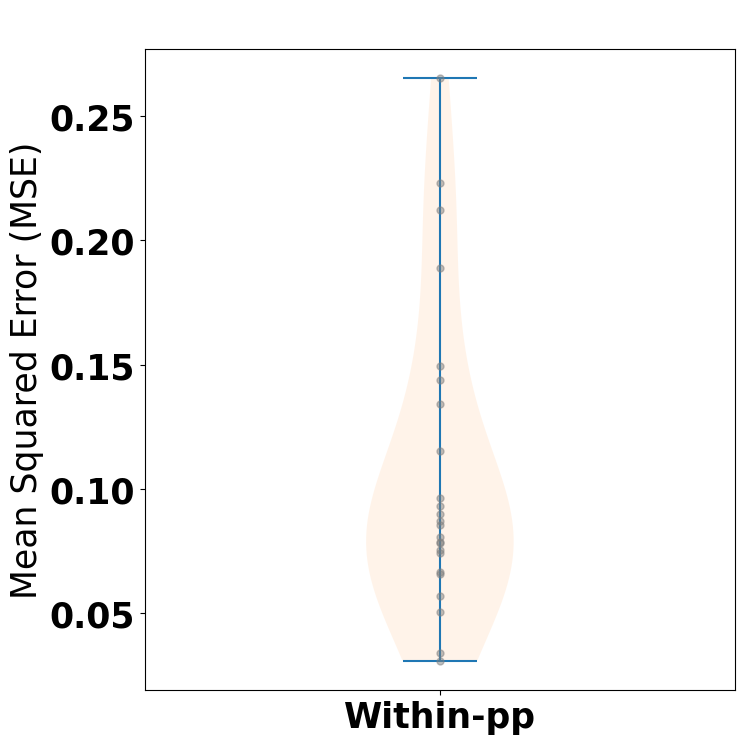

In [16]:
mse_minmax = np.array(mse_all)[:, 2]
mse_adapted = np.array(mse_all)[:, 1]
N = np.array(mse_all).shape[0]

# Create figure
plt.figure(figsize=(8, 8))
fig.set_figheight(6)
fig.set_figwidth(8)
# Boxplots
bplot = plt.violinplot(
    mse_adapted,
    positions=[1.5]
)

for i in range(N):
    plt.plot(
        [1.5],
        [mse_adapted[i]],
        marker='o',
        markersize=5,
        linewidth=1,
        color="grey",
        alpha=0.5
    )


colors = ['peachpuff']
# fill with colors
for patch, color in zip(bplot['bodies'], colors):
    patch.set_facecolor(color)

# Formatting
plt.xticks([1.5], ['Within-pp'])
plt.ylabel('Mean Squared Error (MSE)')
plt.title(' ')
plt.xlim(0.5, 2.5)

plt.tight_layout()
plt.savefig('D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/MSE_values_withinpp.pdf',bbox_inches='tight',dpi=300)
plt.show()

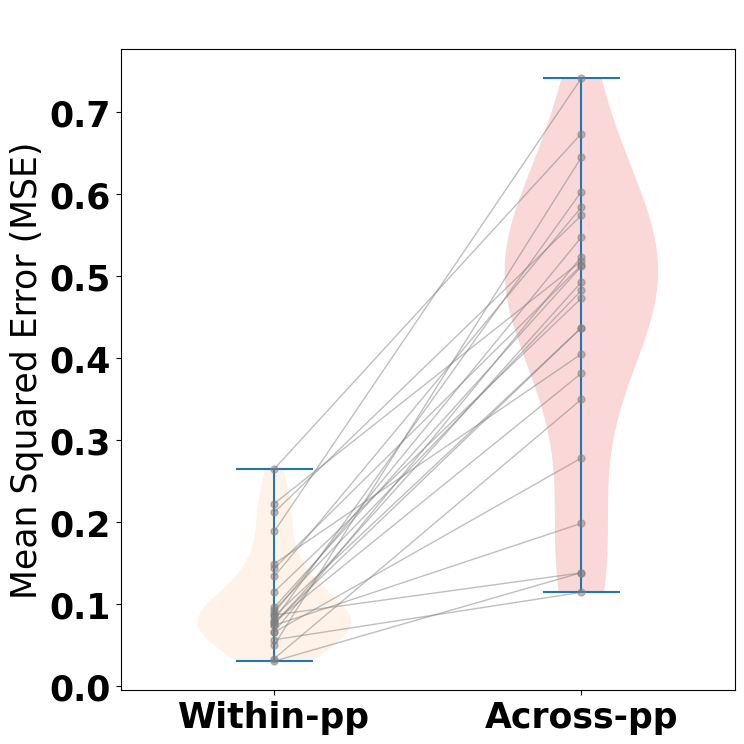

In [13]:
mse_minmax = np.array(mse_all)[:, 2]
mse_adapted = np.array(mse_all)[:, 1]
N = np.array(mse_all).shape[0]

# Create figure
plt.figure(figsize=(8, 8))
fig.set_figheight(6)
fig.set_figwidth(8)
# Boxplots
bplot = plt.violinplot(
    [mse_adapted,mse_minmax],
    positions=[1, 2],
    widths=0.5,
)

colors = ['peachpuff', 'lightcoral']
# fill with colors
for patch, color in zip(bplot['bodies'], colors):
    patch.set_facecolor(color)

# Plot paired points and connecting lines
for i in range(N):
    plt.plot(
        [1, 2],
        [mse_adapted[i],mse_minmax[i]],
        marker='o',
        markersize=5,
        linewidth=1,
        color="grey",
        alpha=0.5
    )

# Formatting
plt.xticks([1, 2], ['Within-pp','Across-pp'])
plt.ylabel('Mean Squared Error (MSE)')
plt.title(' ')
plt.xlim(0.5, 2.5)

plt.tight_layout()
plt.savefig('D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/MSE_values.pdf',bbox_inches='tight',dpi=300)
plt.show()

In [24]:
from scipy.optimize import curve_fit
from sklearn.mixture import GaussianMixture

participants = ['P1','P2','P3','P4','P5','P6','P7','P8','P9','P10',\
                    'P11','P12','P13','P14','P15','P16','P17','P18','P19','P20',\
                    'P21','P22','P23','P24']
# participants = ["P24"]

window_size = 0.35
# participants = ['P1','P2','P3','P4']
def full_preprocessed_data(path,participant):
    return np.load(path+"full_preprocess_data_"+participant+".npy")

mse_all = []
rmse_all = []

# plt.figure(figsize=(20,25))
for ind_part in range(len(participants)):
    for i in range(250):
    
        true_popt_Gen = overall_theta_RNN_Sim2Sim_true_Inv[ind_part][i]
        true_popt_Perso = overall_theta_RNN_Sim2Sim_true_Inv_Perso[ind_part][i]
        true_popt_AllCode = overall_theta_RNN_Sim2Sim_true_Inv_AllCode[ind_part][i]
        
        true_sim_vep_Gen = f(t,true_popt_Gen[0],true_popt_Gen[1],true_popt_Gen[2],true_popt_Gen[3],true_popt_Gen[4],true_popt_Gen[5],true_popt_Gen[6],true_popt_Gen[7],true_popt_Gen[8])
        true_sim_vep_Perso = f(t,true_popt_Perso[0],true_popt_Perso[1],true_popt_Perso[2],true_popt_Perso[3],true_popt_Perso[4],true_popt_Perso[5],true_popt_Perso[6],true_popt_Perso[7],true_popt_Perso[8])
        true_sim_vep_AllCode = f(t,true_popt_AllCode[0],true_popt_AllCode[1],true_popt_AllCode[2],true_popt_AllCode[3],true_popt_AllCode[4],true_popt_AllCode[5],true_popt_AllCode[6],true_popt_AllCode[7],true_popt_AllCode[8])


        # popt, pcov = curve_fit(f, t, evoked, p0=[0.157,0.20, 0.29, -0.25, 0.9, -0.01, 0.01, 0.03, 0.01])
        obs_popt_Gen = overall_theta_RNN_Sim2Sim_obs_Inv[ind_part][i]
        obs_popt_Perso = overall_theta_RNN_Sim2Sim_obs_Inv_Perso[ind_part][i]
        obs_popt_AllCode = overall_theta_RNN_Sim2Sim_obs_Inv_AllCode[ind_part][i]
        obs_sim_vep_Perso = f(t,obs_popt_Perso[0],obs_popt_Perso[1],obs_popt_Perso[2],obs_popt_Perso[3],obs_popt_Perso[4],obs_popt_Perso[5],obs_popt_Perso[6],obs_popt_Perso[7],obs_popt_Perso[8])
        obs_sim_vep_Gen = f(t,obs_popt_Gen[0],obs_popt_Gen[1],obs_popt_Gen[2],obs_popt_Gen[3],obs_popt_Gen[4],obs_popt_Gen[5],obs_popt_Gen[6],obs_popt_Gen[7],obs_popt_Gen[8])
        obs_sim_vep_AllCode = f(t,obs_popt_AllCode[0],obs_popt_AllCode[1],obs_popt_AllCode[2],obs_popt_AllCode[3],obs_popt_AllCode[4],obs_popt_AllCode[5],obs_popt_AllCode[6],obs_popt_AllCode[7],obs_popt_AllCode[8])


        mse_Gen = np.mean((true_sim_vep_Gen - obs_sim_vep_Gen) ** 2)
        mse_Perso = np.mean((true_sim_vep_Perso - obs_sim_vep_Perso) ** 2)
        mse_AllCode = np.mean((true_sim_vep_AllCode - obs_sim_vep_AllCode) ** 2)

        mse_all.append([mse_Gen,mse_Perso, mse_AllCode])

        rmse_Gen = np.square(np.mean((true_sim_vep_Gen - obs_sim_vep_Gen) ** 2))
        rmse_Perso = np.square(np.mean((true_sim_vep_Perso - obs_sim_vep_Perso) ** 2))
        rmse_AllCode = np.square(np.mean((true_sim_vep_AllCode - obs_sim_vep_AllCode) ** 2))

        rmse_all.append([rmse_Gen,rmse_Perso, rmse_AllCode])

        # plt.subplot(8,3,ind_part+1)
        # plt.plot(t,true_sim_vep_Gen, label="true_GEN", color="blue")
        # plt.plot(t,true_popt_Perso, label="True_Perso", color="orange")
        # plt.plot(t,obs_sim_vep_Gen, label="Obs_GEN", color="green")
        # plt.plot(t,obs_sim_vep_Perso, label="Obs_Perso", color="green")
        # plt.plot(t,sim_vep_inf, label="inf evoked")
        # plt.plot(t,sim_vep_sup, label="max evoked")
        # plt.title(participants[ind_part])

# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# plt.show()

In [25]:
np.mean(mse_all, axis=0),np.std(mse_all,axis=0),np.mean(rmse_all, axis=0)

(array([0.28541736, 0.07872855, 0.11083503]),
 array([0.25802266, 0.0748551 , 0.1371823 ]),
 array([0.14803876, 0.01180147, 0.03110339]))

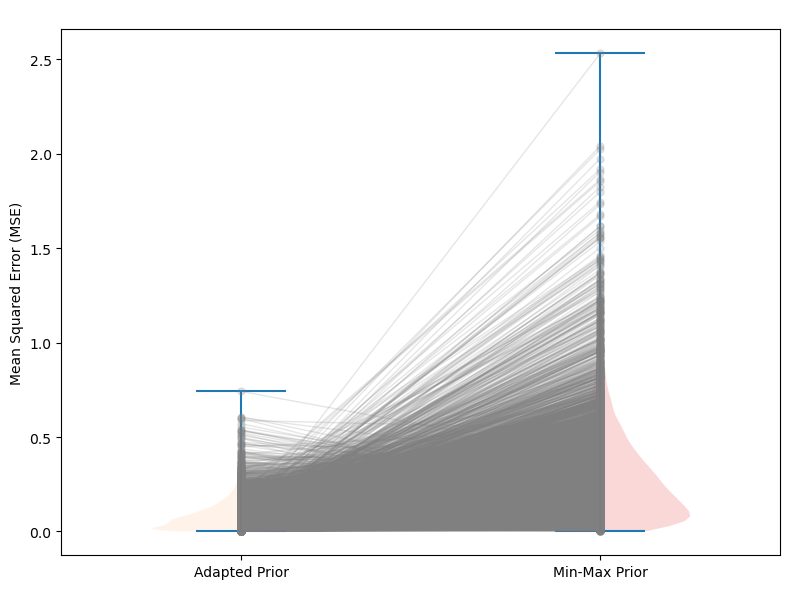

In [21]:
mse_minmax = np.array(mse_all)[:, 0]
mse_adapted = np.array(mse_all)[:, 1]
N = np.array(mse_all).shape[0]

# Create figure
fig = plt.figure(figsize=(8, 8))
fig.set_figheight(6)
fig.set_figwidth(8)
# Boxplots
bplot = plt.violinplot(
    [mse_adapted,mse_minmax],
    positions=[1, 2],
    widths=0.5,
)

colors = ['peachpuff', 'lightcoral']
# fill with colors
for patch, color in zip(bplot['bodies'], colors):
    patch.set_facecolor(color)

# Plot paired points and connecting lines
for i in range(N):
    plt.plot(
        [1, 2],
        [mse_adapted[i],mse_minmax[i]],
        marker='o',
        markersize=5,
        linewidth=1,
        color="grey",
        alpha=0.2
    )

# Formatting
plt.xticks([1, 2], ['Adapted Prior','Min-Max Prior'])
plt.ylabel('Mean Squared Error (MSE)')
plt.title(' ')
plt.xlim(0.5, 2.5)

plt.tight_layout()
plt.savefig('D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/MSE_values.pdf',bbox_inches='tight',dpi=300)
plt.show()

In [3]:
overall_RMSE_RNN_Sim2Sim_true_Inv = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/RMSE_RNN_Sim2Sim_true_Inv"+str(i)+".npy") for i in range(24)])
overall_RMSE_RNN_Sim2Sim_true_Inv_Perso = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/RMSE_RNN_Sim2Sim_true_Inv_Perso"+str(i)+".npy") for i in range(24)])

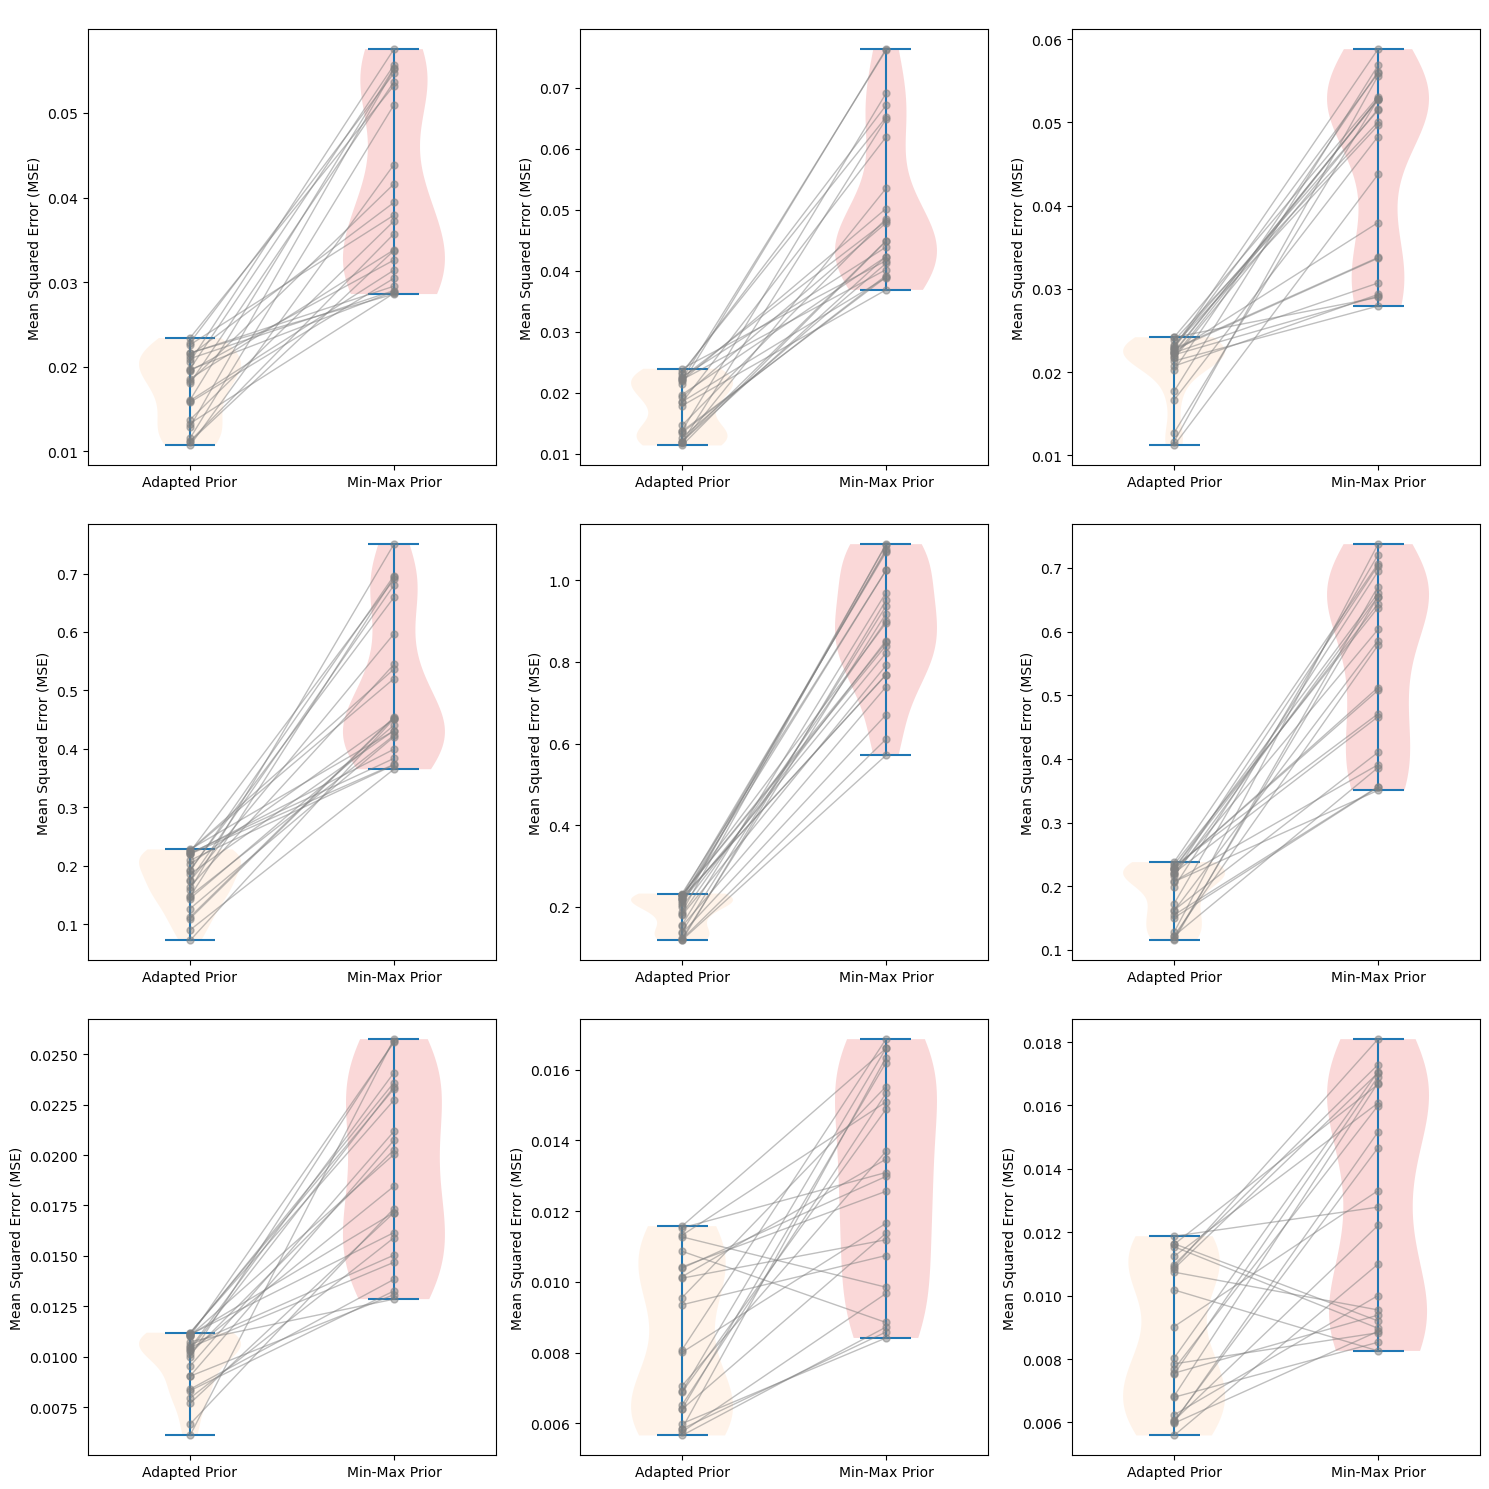

In [50]:
# Create figure
fig = plt.figure(figsize=(15, 15))
# fig.set_figheight(6)
# fig.set_figwidth(8)

for i in range(9):
    plt.subplot(3,3,i+1)
    mse_minmax = np.array(np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv)))[:,i]
    mse_adapted = np.array(np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv_Perso)))[:,i]
    N = np.array(mse_minmax).shape[0]


    # Boxplots
    bplot = plt.violinplot(
        [mse_adapted,mse_minmax],
        positions=[1, 2],
        widths=0.5,
    )

    colors = ['peachpuff', 'lightcoral']
    # fill with colors
    for patch, color in zip(bplot['bodies'], colors):
        patch.set_facecolor(color)

    # Plot paired points and connecting lines
    for i in range(N):
        plt.plot(
            [1, 2],
            [mse_adapted[i],mse_minmax[i]],
            marker='o',
            markersize=5,
            linewidth=1,
            color="grey",
            alpha=0.5
        )

    # Formatting
    plt.xticks([1, 2], ['Adapted Prior','Min-Max Prior'])
    plt.ylabel('Mean Squared Error (MSE)')
    plt.title(' ')
    plt.xlim(0.5, 2.5)

plt.tight_layout()
plt.savefig('D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/graphes/MSE_values.pdf',bbox_inches='tight',dpi=300)
plt.show()

In [51]:
np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv)).mean(axis=0), np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv_Perso)).mean(axis=0),np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv)).std(axis=0), np.sqrt(np.sqrt(overall_RMSE_RNN_Sim2Sim_true_Inv_Perso)).std(axis=0)

(array([0.0407766 , 0.05098078, 0.04557313, 0.50904083, 0.88741904,
        0.5607969 , 0.01921324, 0.01284488, 0.01302305], dtype=float32),
 array([0.01755668, 0.0176455 , 0.02071396, 0.17359917, 0.18603243,
        0.18792045, 0.0097277 , 0.00841201, 0.0086989 ], dtype=float32),
 array([0.01051819, 0.0122689 , 0.01057509, 0.12113547, 0.14828664,
        0.12967604, 0.004255  , 0.00282945, 0.00348602], dtype=float32),
 array([0.00406778, 0.00449876, 0.00378043, 0.04584035, 0.04118466,
        0.04291333, 0.00146608, 0.00214455, 0.00223008], dtype=float32))

In [4]:
overall_RMSE_RNN_Sim2Sim_true_Inv

array([[9.7462464e-07, 2.3608338e-06, 7.9482306e-06, 1.7773576e-02,
        4.9870381e-01, 1.6534583e-01, 9.0585857e-08, 3.5131279e-08,
        6.6788246e-08],
       [8.6091444e-07, 2.6020459e-06, 1.0446161e-05, 1.2688653e-01,
        8.8543576e-01, 1.8410474e-01, 4.3250881e-07, 5.7857545e-09,
        7.8030084e-08],
       [1.9195109e-06, 3.1988989e-06, 7.7657551e-06, 3.2012857e-02,
        3.9230362e-01, 2.6925069e-01, 3.6681236e-08, 1.6740122e-08,
        8.4046832e-08],
       [6.6831529e-07, 4.0373025e-06, 9.8871205e-06, 3.1297781e-02,
        6.5891552e-01, 2.4517055e-01, 2.9378569e-07, 2.8395203e-08,
        8.4785086e-08],
       [6.9699234e-07, 2.8775139e-06, 2.0767779e-06, 4.1297004e-02,
        4.5607463e-01, 2.3333505e-02, 4.6489195e-08, 1.8453630e-08,
        6.4726451e-09],
       [1.1309046e-06, 5.2209534e-06, 7.0487505e-07, 3.1697613e-01,
        2.9826304e-01, 2.8345028e-02, 8.6336449e-08, 2.4893776e-08,
        2.2247468e-08],
       [8.0227692e-06, 1.8426779e-06, 9.

In [ ]:
theta_all = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv"+str(i)+".npy") for i in range(24)])
theta_sim = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv"+str(i)+".npy") for i in range(24)])


# theta_all = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_obs_Inv_Perso"+str(i)+".npy") for i in range(24)])
# theta_sim = np.array([np.load("D:/s.velut/Documents/These/DCC/SBI/results/overall_sbi/theta_RNN_Sim2Sim_true_Inv_Perso"+str(i)+".npy") for i in range(24)])

theta_all.shape, theta_sim.shape

np.mean([np.sqrt(np.mean((theta_all[i]-theta_sim[i])**2,axis=0)) for i in range(24)], axis=0)

array([0.03978793, 0.04568839, 0.03933256, 0.4124237 , 0.73258954,
       0.45079386, 0.01763265, 0.01110408, 0.01342921], dtype=float32)

In [47]:
np.mean((theta_all[0] - theta_sim[0])**2,axis=0)
np.sqrt(1.58e-03)

np.float64(0.03974921382870358)